# Data Science Fundamentals Assessment
**Student:** Tallapureddy Aparna Reddy · **Internship submission** · **GitHub:** `appureddy1102-cloud`

This notebook introduces Python, statistical thinking, data types, preprocessing, EDA, common libraries and a reproducible mini-project. The 160-row dataset is **synthetic educational sample data**, generated with a fixed random seed; it does not describe real company performance.

## Learning objectives
Understand core Python and data structures; calculate and interpret foundational statistics; clean tabular data; summarize and visualize patterns; explain basic machine-learning concepts; follow reproducible, privacy-conscious practices.

Run from the repository root after `pip install -r requirements.txt`.

## 1. Python fundamentals

In [1]:
# Variables, basic types and operators
name = "Aparna"          # str
orders = 4               # int
revenue = 125.50          # float
is_valid = True           # bool
print(name, orders, revenue, is_valid)
print("revenue per order:", revenue / orders)

# Conditional, loop and function
def classify_order(value):
    if value >= 100:
        return "large"
    return "standard"

for value in [45, 125]:
    print(classify_order(value))

# Collections and safe exception handling
items = ["pen", "notebook"]        # mutable list
coordinates = (17.4, 78.5)           # immutable tuple
prices = {"pen": 10, "notebook": 50} # key-value dictionary
regions = {"North", "South", "North"} # unique set values
try:
    print(10 / 0)
except ZeroDivisionError as exc:
    print(type(exc).__name__, "handled safely")

Aparna 4 125.5 True
revenue per order: 31.375
standard
large
ZeroDivisionError handled safely


**Expected output** (verified by executing this cell): `Aparna 4 125.5 True`, `revenue per order: 31.375`, `standard`, `large`, `ZeroDivisionError handled safely`. Lists, tuples, dictionaries and sets serve different access and uniqueness needs.

## 2. Statistical foundations

In [2]:
import numpy as np
from statistics import multimode
x = np.array([2, 4, 4, 6], dtype=float)
print("mean", x.mean(), "median", np.median(x), "mode", multimode(x.tolist()))
print("range", x.max()-x.min(), "population variance", x.var(), "population SD", x.std())
print("sample variance", x.var(ddof=1), "sample SD", x.std(ddof=1))
print("Q1, Q3, IQR", *np.quantile(x,[.25,.75]), np.quantile(x,.75)-np.quantile(x,.25))
# Correlation example; association does not imply causation
print("Pearson r", np.corrcoef([1,2,3],[2,4,6])[0,1])

mean 4.0 median 4.0 mode [4.0]
range 4.0 population variance 2.0 population SD 1.4142135623730951
sample variance 2.6666666666666665 sample SD 1.632993161855452
Q1, Q3, IQR 3.5 4.5 1.0
Pearson r 1.0


For `[2, 4, 4, 6]`, mean=4, median=4, mode=4, range=4, population variance=2, population SD≈1.414; sample variance≈2.667 and sample SD≈1.633. Quartiles depend on convention; NumPy linear interpolation gives Q1=3.5, Q3=4.5, IQR=1. Probability of an even result on a fair six-sided die is 3/6=0.5. Hypothesis testing sets H0/H1, chooses a test, calculates a statistic and p-value, compares with a prespecified α, and interprets uncertainty—not proof of a claim.

## 3. Data types and Python structures

Numerical values may be **discrete** (counts) or **continuous** (measurements). Categorical values may be **nominal** (unordered region) or **ordinal** (low/medium/high). Structured data fits rows and columns; semi-structured data includes JSON key-value records; unstructured examples include images, audio and free text. Python `list` preserves order and is mutable; `tuple` is an immutable sequence; `dict` maps keys to values; `set` stores unique elements. NumPy arrays support efficient homogeneous numerical computation; Pandas Series/DataFrames add labeled, tabular operations.

## 4. Create, load and validate the educational dataset

In [3]:
from pathlib import Path
import pandas as pd
from src.data_analysis import create_sample_dataset, load_and_clean, analyze, make_charts, OUTPUT_DIR
ROOT=Path.cwd()
raw_path=ROOT/"data"/"sample_dataset.csv"
if not raw_path.exists(): create_sample_dataset(raw_path)
raw=pd.read_csv(raw_path)
print("raw shape:",raw.shape,"missing cells:",int(raw.isna().sum().sum()),"exact duplicate rows:",int(raw.duplicated().sum()))
print("raw types:\n",raw.dtypes.to_string())
df,audit=load_and_clean(raw_path)
print("audit:",audit)
print("clean missing:",int(df.isna().sum().sum()),"duplicates:",int(df.duplicated().sum()))

raw shape: (161, 11) missing cells: 3 exact duplicate rows: 1
raw types:
 order_date      object
order_id        object
customer_id     object
region          object
segment         object
category        object
units            int64
unit_price     float64
discount       float64
revenue        float64
profit         float64
audit: {'raw_rows': 161, 'raw_missing_cells': 3, 'exact_duplicates': 1, 'incomplete_core_rows_removed': 3, 'clean_rows': 157, 'date_min': '2025-01-01', 'date_max': '2025-06-30'}
clean missing: 0 duplicates: 0


The generator is deterministic (`seed=42`) and documents intentionally imperfect data (3 missing region values and one duplicate row). The cleaning function counts and removes exact duplicates, parses date/numeric columns, removes incomplete core records and validates basic numeric ranges. This makes the quality checks inspectable rather than silently assuming clean data.

## 5. Descriptive analysis and EDA

In [4]:
kpis, numerical, category, monthly, rho = analyze(df)
print("KPI summary:",kpis)
display(numerical.round(2))
display(category.round(2))
display(monthly.round(2))
print("Spearman discount-profit-margin association:",round(rho,3))

KPI summary: {'revenue': 46034.090000000004, 'profit': 7614.859999999999, 'orders': 157, 'customers': 54, 'aov': 293.2107643312102, 'mean_discount': 0.07738853503184713, 'profit_margin': 0.16541784577472907}


,count,mean,std,min,25%,50%,75%,max
units,157.0,4.76,2.27,1.00,3.00,5.00,7.00,8.00
unit_price,157.0,64.95,43.93,17.55,25.06,50.26,99.95,161.42
discount,157.0,0.08,0.07,0.00,0.00,0.05,0.10,0.20
revenue,157.0,293.21,278.73,15.89,98.24,177.01,448.98,1237.12
profit,157.0,48.50,52.83,-2.92,16.63,30.12,56.06,264.15


,orders,revenue,profit,profit_margin
category,,,,
Electronics,53,30078.10,4521.26,0.15
Home Goods,36,8691.87,1463.67,0.17
Office Supplies,68,7264.12,1629.93,0.22


,revenue,profit
month,,
2025-01-01,9530.96,1354.12
2025-02-01,9599.26,1890.70
2025-03-01,9650.36,1449.62
2025-04-01,5774.72,876.80
2025-05-01,5560.03,1168.72
2025-06-01,5918.76,874.90


Spearman discount-profit-margin association: -0.843


**Interpretation:** revenue/profit are totals over cleaned sample transactions; category profit margin is aggregated profit divided by aggregated revenue. Spearman rho captures monotonic association and is not a causal effect. Small synthetic data should be treated as a coding exercise, not market evidence.

revenue_distribution.png


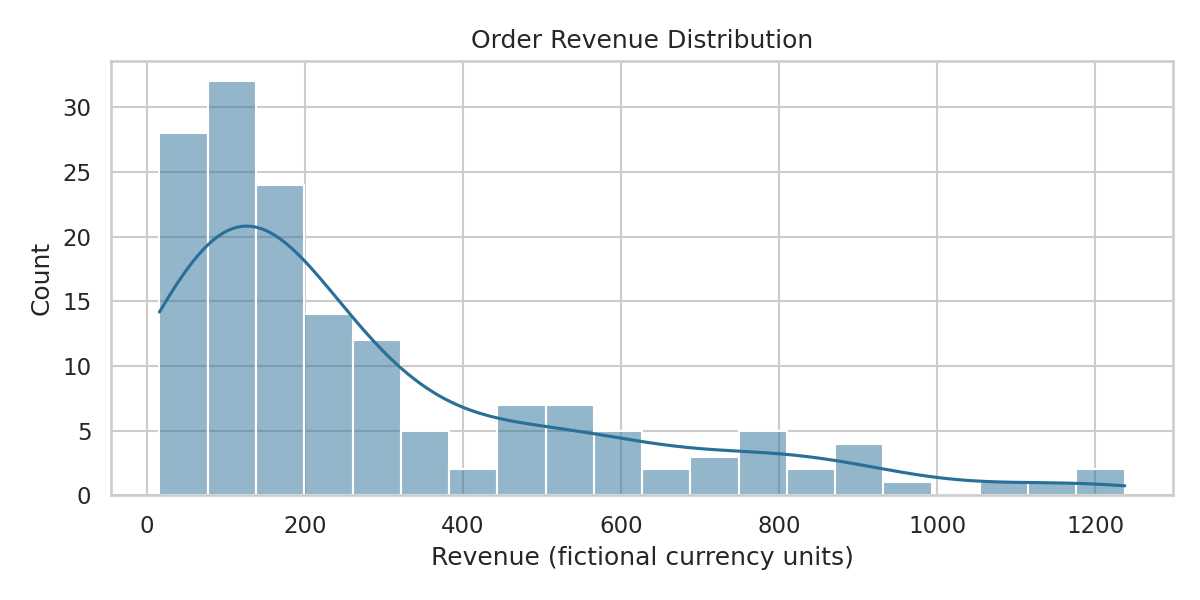

profit_by_category.png


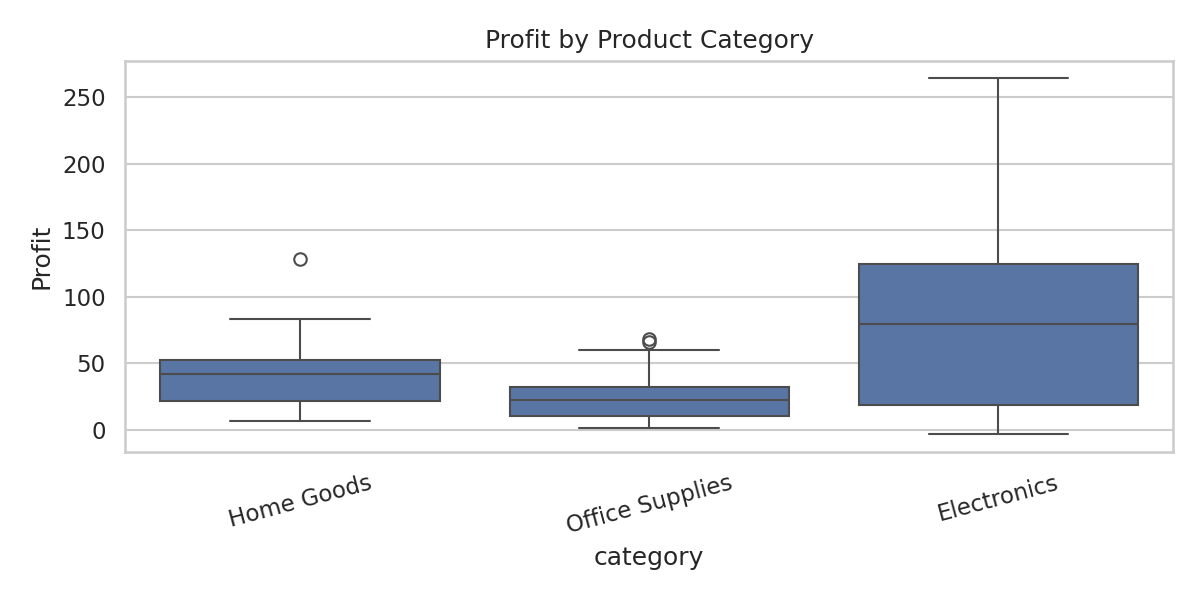

monthly_revenue.png


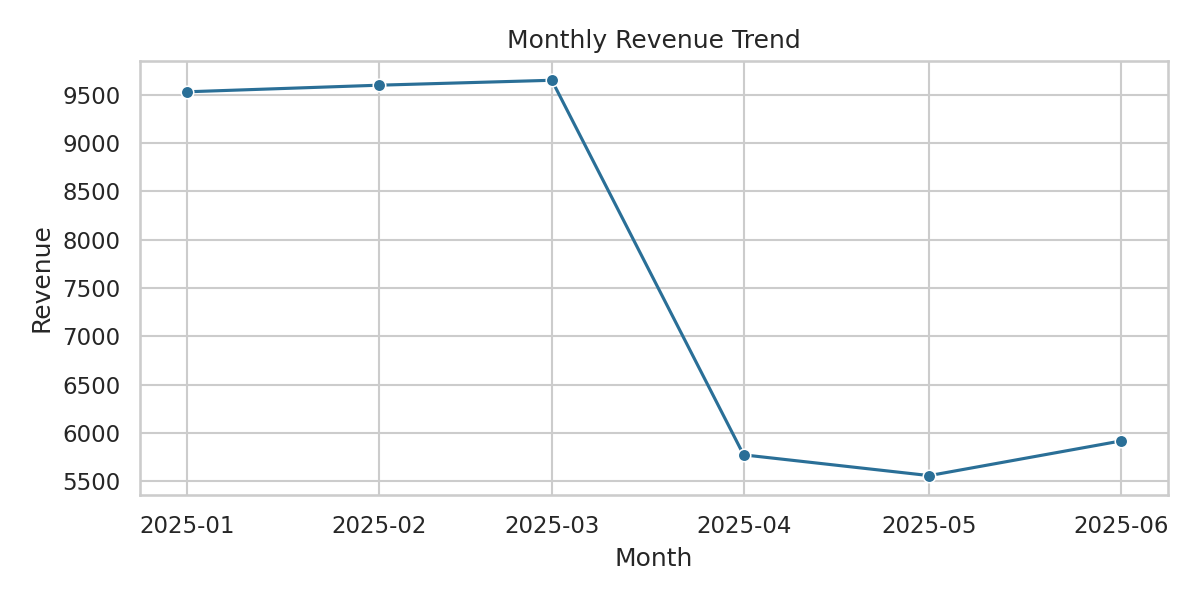

correlation_heatmap.png


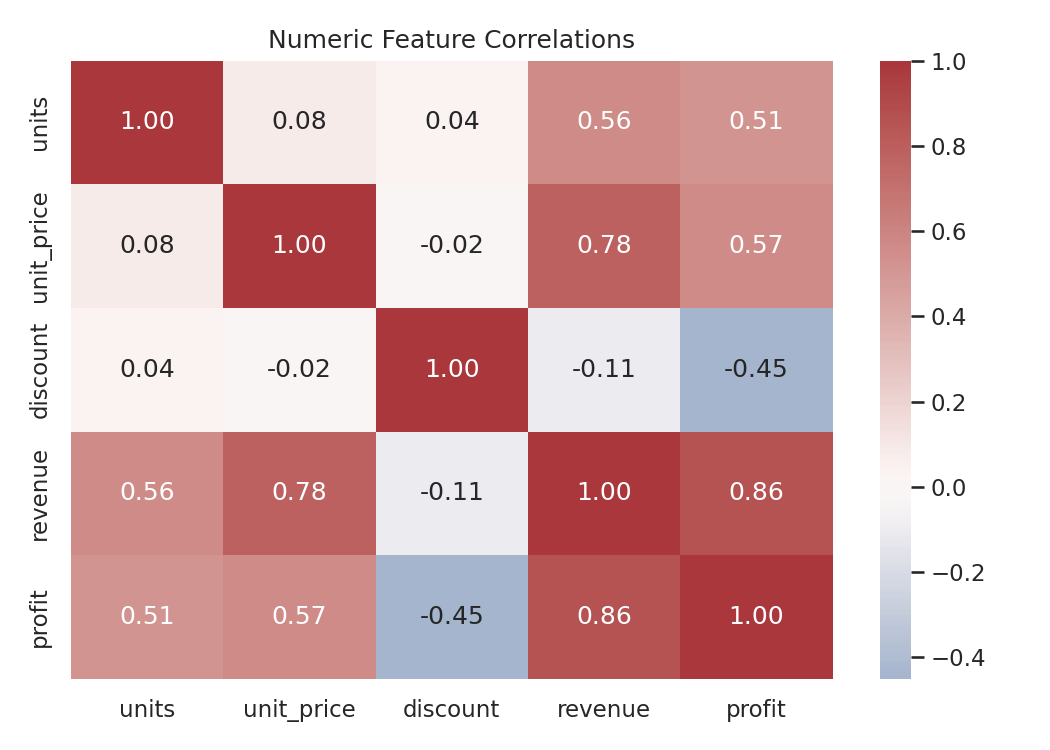

discount_profit_scatter.png


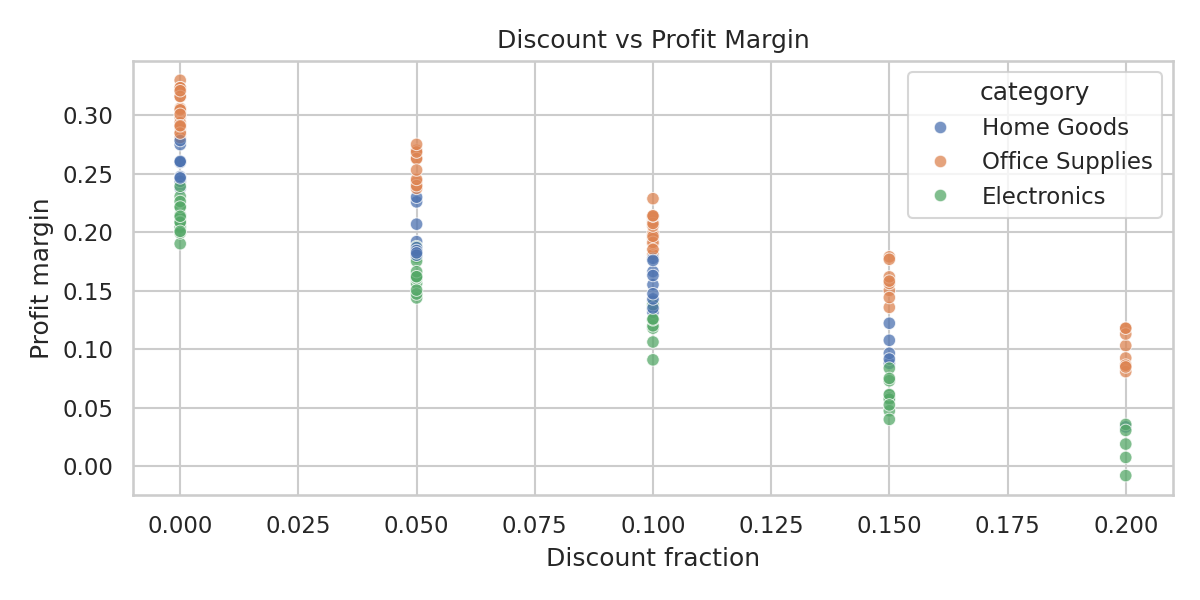

In [5]:
charts=make_charts(df,OUTPUT_DIR)
from IPython.display import display, Image
for p in charts:
    print(p.name)
    display(Image(filename=str(p)))

These plots show a numeric distribution, category boxplots, monthly trend, numeric correlation heatmap and discount-profit-margin scatter. Histograms and boxplots reveal shape and potential extreme observations; a marked outlier is a point to investigate, not automatically delete.

## 6. Demonstrations of essential libraries

NumPy squared: [1 4 9]
Pandas category means:
 category
Electronics        567.51
Home Goods         241.44
Office Supplies    106.83
Name: revenue, dtype: float64


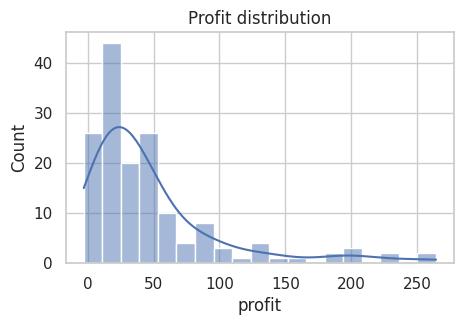

In [6]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score
# NumPy: vectorized arithmetic; Pandas: grouped summary
a=np.array([1,2,3]); print("NumPy squared:",a**2)
print("Pandas category means:\n",df.groupby("category").revenue.mean().round(2))
# Matplotlib and Seaborn: compact plot
fig,ax=plt.subplots(figsize=(5,3)); sns.histplot(df.profit,kde=True,ax=ax); ax.set_title("Profit distribution"); plt.show()

**Library roles:** NumPy provides arrays, vectorization and numerical functions. Pandas handles labeled tabular data, joins, missing values and group operations. Matplotlib supplies flexible plotting primitives; Seaborn adds statistical chart defaults. Scikit-learn offers preprocessing, estimators, model validation and metrics.

## 7. Basic machine learning example: regression

In [7]:
# Predict synthetic revenue using quantities/prices/discounts; demonstration only
X=df[["units","unit_price","discount"]]
y=df["revenue"]
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=.2,random_state=42)
model=LinearRegression().fit(X_train,y_train)
pred=model.predict(X_test)
print("MAE:",round(mean_absolute_error(y_test,pred),2),"R2:",round(r2_score(y_test,pred),3))

MAE: 68.18 R2: 0.749


Supervised learning learns from labeled examples: regression predicts continuous outcomes, classification predicts classes. Unsupervised learning finds patterns without labeled targets; clustering groups similar records. Train/test separation estimates performance on held-out examples. Overfitting occurs when a model captures noise or training-specific patterns and generalizes poorly; use validation, simpler models, regularization and appropriate metrics. This tiny synthetic example is pedagogical, not a deployed predictive model.

## 8. Industry best practices

Use descriptive names, small functions, consistent formatting and comments explaining intent. Fix random seeds for reproducibility; record sources, assumptions, package versions and cleaning changes. Keep credentials out of code and repositories; minimize personal data, restrict access and follow retention rules. Use version control (Git), review changes, document limitations, check for bias and unintended harms, communicate uncertainty, and avoid claims unsupported by data. Protect test sets from leakage and distinguish exploratory analysis from confirmatory testing.

## 9. Mini-project conclusions

In [8]:
print(f"Clean records: {len(df)}; rows removed: {audit['raw_rows']-audit['clean_rows']}.")
print(f"Revenue: {kpis['revenue']:.2f}; profit: {kpis['profit']:.2f}; AOV: {kpis['aov']:.2f}; customers: {kpis['customers']}.")
print("Highest-revenue category:",category.revenue.idxmax())
print("Largest category margin:",category.profit_margin.idxmax())
print("Lowest category margin:",category.profit_margin.idxmin())
print("Discount/profit margin Spearman rho:",round(rho,3))

Clean records: 157; rows removed: 4.
Revenue: 46034.09; profit: 7614.86; AOV: 293.21; customers: 54.
Highest-revenue category: Electronics
Largest category margin: Office Supplies
Lowest category margin: Electronics
Discount/profit margin Spearman rho: -0.843


The generated data creates realistic variation for demonstrating inspection, cleaning, summaries and visualization. Any relationship reflects the data-generation process and must not be generalized to an actual company. The exercise demonstrates an end-to-end workflow and honest communication of limitations.

## 10. Assessment questions and answers
1. **What is a variable?** A named reference to a value.
2. **List vs tuple?** Lists are mutable; tuples are immutable sequences.
3. **What is a dictionary?** A mapping of unique keys to values.
4. **What does a set do?** Stores unique items and supports set operations.
5. **Mean vs median?** Mean averages values; median is the middle after sorting and is more robust to extreme values.
6. **What does standard deviation measure?** Typical spread around the mean in original units.
7. **Correlation implies causation?** No; confounding and reverse causality may explain association.
8. **What is a p-value?** Under H0 and model assumptions, the probability of results at least as extreme as observed.
9. **Nominal vs ordinal?** Unordered categories vs categories with a meaningful order.
10. **What is an outlier?** An observation unusual relative to a distribution; verify before changing/removing.
11. **Why handle missing values?** Missingness can break calculations or bias results; choose a documented strategy.
12. **What is standardization?** Rescaling to zero mean/unit standard deviation (typically); useful for scale-sensitive methods.
13. **What does EDA do?** Summarizes structure, quality, distributions and relationships before modeling.
14. **Regression vs classification?** Continuous target vs categorical target.
15. **What is overfitting?** Excellent training fit but weak generalization.
16. **Why set random seeds?** To make randomized steps more reproducible.
17. **Why use a train/test split?** To evaluate performance on unseen examples.
18. **How protect data?** Minimize collection, control access, remove secrets, document use and follow applicable privacy rules.

## Conclusion and learning outcomes

This assessment demonstrates foundational Python programming, data structures, statistics, preprocessing, EDA, visual communication, a basic supervised-learning workflow, reproducibility and responsible data practices. The mini-project is intentionally synthetic and provides a safe practice setting for a complete data-science lifecycle. See the Word report for expanded explanations, code examples and references.